# Hurst Regimes 03 — volatility roughness with seasonality, mean reversion and SMM

**Discussion:** `discussions/Hurst_Regimes/005_claude_03_review_fixes.md` · **Code:** `src/data_engineering/modeling/rough_vol_smm.py`

This notebook implements the HR 004 review fixes.

1. **Seasonality.** Returns are deseasonalized by day-of-week × time-of-day. Lags at multiples of 24 h and 7 days are excluded from every fit.
2. **Mean reversion as its own parameter.** Discrete fOU + noise structure function on hourly $\log\sigma$:
   $$m_2(k)=2V\,[1-\rho_{fOU}(k;H,\kappa)]+2\eta^2.$$
   This treats hourly log RV as a point value (integration over the hour is ignored), so it is an approximation.
3. **Primary estimator: simulated method of moments over $(H,\kappa,\nu,\text{df})$.**
   - Model: $\log\sigma$ follows an fOU at 5-minute steps; returns are $s_{dow,tod}\,\sigma_t\,\varepsilon_t$ with $\varepsilon\sim t(\text{df})$.
   - Each simulation runs on the data's own timestamps, gaps and seasonal profile, and goes through the identical pipeline (seasonal re-estimation, 1h/4h/1d RV, logs, 18 moments).
   - Common random numbers, 10 replicates, $H$ grid from 0.005, sandwich standard errors.
   - Parameter recovery is checked on synthetic data with the same layout before the real fits.

Descriptive only: no gate, no trading claim.

Environment (optional): `HR_HISTORY_DIR`, `HR_ASSETS`, `HR03_RECOVERY` (default 1; set 0 to skip the about 20-minute recovery check).

In [1]:
from pathlib import Path
import json, os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 60)
load_dotenv()
DATA_ROOT = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    raise RuntimeError('Repository root not found.')
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from data_engineering.modeling import hurst_regimes as hr
from data_engineering.modeling import hurst_roughness as rg
from data_engineering.modeling import rough_vol_smm as sm

HIST_DIR = Path(os.getenv('HR_HISTORY_DIR', str(DATA_ROOT / 'history' / 'price_5m')))
ASSETS = [x.strip().upper() for x in os.getenv('HR_ASSETS', 'AVAX,BTC,ETH,SOL,TRX,XRP').split(',') if x.strip()]
RECOVERY = os.getenv('HR03_RECOVERY', '1').strip() != '0'
OUT = PROJECT_ROOT / 'notebooks' / 'Hurst_Regimes' / '03'
OUT.mkdir(parents=True, exist_ok=True)
print('Hurst Regimes 03', sm.VERSION, sm.selftest())
hist = hr.load_history(HIST_DIR, ASSETS)
DATA = {}
for a in sorted(hist.underlying.unique()):
    lp = rg.price_grid(hist, a)
    if lp.notna().sum() < 288 * rg.MIN_DAYS:
        print(f'{a}: excluded (short history)'); continue
    r, slot, idx = sm.day_grid(lp)
    DATA[a] = dict(r=r, slot=slot, idx=idx)
    print(f'{a}: {idx[0]} -> {idx[-1]} | days {len(r) // 288} | missing {np.mean(~np.isfinite(r)):.2%}')

Hurst Regimes 03 0.1.0 {'version': '0.1.0', 'profile_corr': 0.9985, 'ok': True}
AVAX: 2024-09-01 00:05:00+00:00 -> 2026-10-11 00:00:00+00:00 | days 770 | missing 0.00%
BTC: 2024-09-01 00:05:00+00:00 -> 2026-10-11 00:00:00+00:00 | days 770 | missing 0.00%
ETH: 2024-09-01 00:05:00+00:00 -> 2026-10-11 00:00:00+00:00 | days 770 | missing 0.00%
SOL: 2024-09-01 00:05:00+00:00 -> 2026-10-11 00:00:00+00:00 | days 770 | missing 0.00%
TRX: 2024-09-01 00:05:00+00:00 -> 2026-10-11 00:00:00+00:00 | days 770 | missing 0.00%
XRP: 2024-09-01 00:05:00+00:00 -> 2026-10-11 00:00:00+00:00 | days 770 | missing 0.00%


## 1. Seasonality: day-of-week × time-of-day (fix 1)

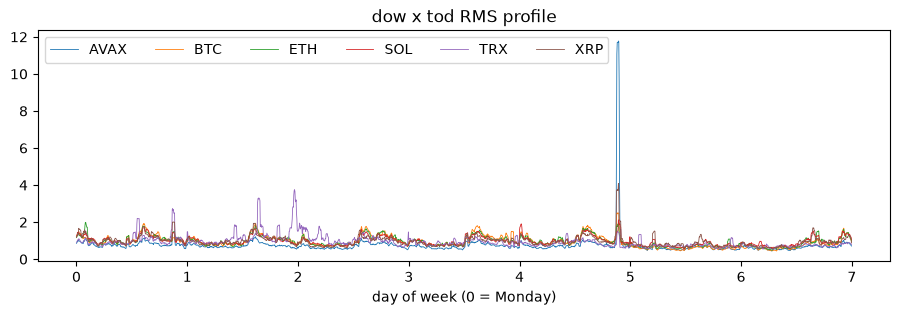

,underlying,acf1h_lag24_tod,acf1h_lag24_dowtod,acf1h_lag168_tod,acf1h_lag168_dowtod,acf1h_lag100_dowtod,rms_Mon,rms_Tue,rms_Wed,rms_Thu,rms_Fri,rms_Sat,rms_Sun
0,AVAX,0.450,0.360,0.370,0.281,0.237,0.832,0.754,0.723,0.717,1.981,0.596,0.651
1,BTC,0.363,0.399,0.414,0.262,0.249,1.124,1.050,1.063,1.078,1.161,0.602,0.795
2,ETH,0.370,0.396,0.340,0.246,0.236,1.139,1.032,1.055,1.015,1.110,0.701,0.877
3,SOL,0.413,0.430,0.339,0.282,0.272,1.123,1.028,1.006,0.995,1.116,0.751,0.934
4,TRX,0.565,0.515,0.489,0.507,0.397,1.092,1.380,1.100,0.916,0.876,0.745,0.727
5,XRP,0.521,0.523,0.395,0.369,0.355,1.149,1.037,0.933,0.947,1.182,0.820,0.876


Descriptive H on pre-declared short lag ranges (no 24h/168h multiples), dow x tod deseasonalized:


H_noise_corr                H_raw              
block                1d     1h     4h     1d     1h     4h
underlying                                                
AVAX              0.210  0.080  0.125  0.212  0.081  0.125
BTC               0.230  0.090  0.125  0.229  0.091  0.128
ETH               0.240  0.080  0.110  0.242  0.082  0.111
SOL               0.250  0.085  0.130  0.249  0.084  0.128
TRX               0.225  0.075  0.140  0.224  0.076  0.139
XRP               0.265  0.100  0.160  0.267  0.100  0.160

In [2]:
season_rows, desc_rows = [], []
fig, ax = plt.subplots(figsize=(11, 3))
for a, d in DATA.items():
    prof = sm.dow_tod_profile(d['r'], d['slot'])
    d['prof'] = prof
    lv_dt = sm.log_vol_all(d['r'], d['slot'], prof)
    lv_t = sm.log_vol_all(d['r'], d['slot'], sm.tod_profile(d['r'], d['slot']))
    d['lv'] = lv_dt
    a1 = rg.acf(lv_t['1h'], 170); a2 = rg.acf(lv_dt['1h'], 170)
    dow_level = (prof.reshape(7, 288) ** 2).mean(1) ** 0.5
    season_rows.append({'underlying': a, 'acf1h_lag24_tod': a1[24], 'acf1h_lag24_dowtod': a2[24],
                        'acf1h_lag168_tod': a1[168], 'acf1h_lag168_dowtod': a2[168], 'acf1h_lag100_dowtod': a2[100],
                        **{f'rms_{dn}': v for dn, v in zip(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], dow_level)}})
    ax.plot(np.arange(2016) / 288, prof, lw=0.6, label=a)
    for b, lags in sm.DESC_LAGS.items():
        sf = rg.structure_function(lv_dt[b], lags)
        z = rg.zeta(sf, 1, max(lags)); nc = rg.noise_corrected_H(sf, 1, max(lags))
        desc_rows.append({'underlying': a, 'block': b, 'lags': str(lags), 'H_raw': z.get('H2'), 'H_noise_corr': nc.get('H_noise_corr'),
                          'noise_share_lag1': nc.get('noise_share_lag1')})
ax.set_xlabel('day of week (0 = Monday)'); ax.set_title('dow x tod RMS profile'); ax.legend(ncol=6); plt.show()
season_tab, desc_tab = pd.DataFrame(season_rows), pd.DataFrame(desc_rows)
display(season_tab.round(3))
print('Descriptive H on pre-declared short lag ranges (no 24h/168h multiples), dow x tod deseasonalized:')
display(desc_tab.pivot_table(index='underlying', columns='block', values=['H_raw', 'H_noise_corr']).round(3))

## 2. Parametric fOU + noise structure function on hourly $\log\sigma$ (fix 2, point approximation)

In [3]:
param_rows = []
t0 = time.time()
for a, d in DATA.items():
    param_rows.append({'underlying': a, **sm.param_fit_1h(d['lv']['1h'])})
    print(f'{a}: done ({time.time() - t0:.0f}s)')
param_tab = pd.DataFrame(param_rows)
display(param_tab.round(4))

AVAX: done (40s)
BTC: done (80s)
ETH: done (121s)
SOL: done (271s)
TRX: done (329s)
XRP: done (378s)


,underlying,H,kappa_per_hour,kappa_per_day,half_life_days,stat_var_V,noise_eta2,noise_share_lag1,rss,at_grid_edge
0,AVAX,0.065,0.0032,0.0759,9.1330,0.2188,0.0016,0.0140,0.0104,False
1,BTC,0.070,0.0018,0.0427,16.2411,0.2532,0.0000,0.0000,0.0140,False
2,ETH,0.065,0.0018,0.0427,16.2411,0.2617,0.0000,0.0000,0.0109,False
3,SOL,0.070,0.0018,0.0427,16.2411,0.2318,0.0000,0.0000,0.0110,False
4,TRX,0.075,0.0056,0.1350,5.1359,0.2268,0.0044,0.0375,0.0193,False
5,XRP,0.090,0.0018,0.0427,16.2411,0.3178,0.0000,0.0000,0.0108,False


## 3. SMM recovery check on synthetic data with the real layout (fix 3)

In [4]:
rec_rows = []
if RECOVERY:
    a0 = list(DATA)[0]
    d = DATA[a0]
    mask = ~np.isfinite(d['r'])
    for th in [(0.05, 0.05, 0.4, 5.0), (0.02, 0.2, 0.4, 4.0)]:
        t0 = time.time()
        rec_rows.append({'layout': a0, **sm.recovery_check(th, d['slot'], mask, d['prof'])})
        print(f'recovery {th}: {time.time() - t0:.0f}s')
rec_tab = pd.DataFrame(rec_rows)
display(rec_tab.round(4))

recovery (0.05, 0.05, 0.4, 5.0): 954s
recovery (0.02, 0.2, 0.4, 4.0): 939s


,layout,H_true,kappa_true,nu_true,df_true,H,H_ci_low,H_ci_high,kappa_per_day,kappa_ci_low,kappa_ci_high,nu,df,max_abs_moment_t
0,AVAX,0.05,0.05,0.4,5.0,0.0994,0.0222,0.1766,0.0990,0.0486,0.2015,0.3080,4.4209,0.8399
1,AVAX,0.02,0.20,0.4,4.0,0.0310,0.0104,0.0515,0.2043,0.0950,0.4394,0.3278,3.7766,1.5618


## 4. SMM estimates of $(H,\kappa,\nu,\text{df})$

In [5]:
smm_rows, mom_tabs = [], []
for a, d in DATA.items():
    t0 = time.time()
    f = sm.fit(d['r'], d['slot'])
    smm_rows.append({'underlying': a, **f['summary']})
    mom_tabs.append(f['moments'].assign(underlying=a))
    print(f"{a}: H={f['summary']['H']:.3f} [{f['summary']['H_ci_low']:.3f}, {f['summary']['H_ci_high']:.3f}] "
          f"kappa/day={f['summary']['kappa_per_day']:.4f} half-life={f['summary']['half_life_days']:.1f} d "
          f"df={f['summary']['df']:.1f} max|t|={f['summary']['max_abs_moment_t']:.2f} ({time.time() - t0:.0f}s)")
smm_tab = pd.DataFrame(smm_rows)
mom_tab = pd.concat(mom_tabs, ignore_index=True)
display(smm_tab.round(4))
display(mom_tab.pivot_table(index='moment', columns='underlying', values='t').reindex(sm.MOMENT_NAMES).round(2))

AVAX: H=0.098 [0.064, 0.132] kappa/day=0.6622 half-life=1.0 d df=92.0 max|t|=14.26 (733s)
BTC: H=0.089 [0.055, 0.123] kappa/day=0.4370 half-life=1.6 d df=92.0 max|t|=11.21 (706s)
ETH: H=0.088 [0.055, 0.122] kappa/day=0.5007 half-life=1.4 d df=92.0 max|t|=11.81 (700s)
SOL: H=0.095 [0.061, 0.130] kappa/day=0.3711 half-life=1.9 d df=92.0 max|t|=11.84 (679s)
TRX: H=0.071 [0.038, 0.104] kappa/day=0.0981 half-life=7.1 d df=92.0 max|t|=9.95 (693s)
XRP: H=0.110 [0.080, 0.141] kappa/day=0.1640 half-life=4.2 d df=92.0 max|t|=11.85 (682s)


,underlying,H,H_se,H_ci_low,H_ci_high,kappa_per_day,kappa_ci_low,kappa_ci_high,half_life_days,half_life_ci_low,half_life_ci_high,nu,nu_se,df,df_se,stat_var_log_sigma,objective,nm_evals,nm_converged,grid_best_H,grid_best_kappa,df_stage0,max_abs_moment_t,kappa_identified
0,AVAX,0.0982,0.0175,0.0639,0.1324,0.6622,0.5054,0.8677,1.0467,0.7988,1.3714,0.6736,0.0293,92.0078,382.1866,0.2261,787.6116,360,False,0.15,1.0,30.0,14.2631,True
1,BTC,0.0890,0.0173,0.0550,0.1229,0.4370,0.3132,0.6098,1.5861,1.1366,2.2133,0.6941,0.0373,92.0103,478.5791,0.2580,495.4379,360,False,0.15,1.0,10.0,11.2075,True
2,ETH,0.0884,0.0170,0.0552,0.1217,0.5007,0.3655,0.6858,1.3844,1.0107,1.8964,0.7329,0.0380,91.9517,518.6995,0.2806,693.9402,360,False,0.15,1.0,10.0,11.8140,True
3,SOL,0.0953,0.0174,0.0611,0.1295,0.3711,0.2587,0.5323,1.8680,1.3021,2.6798,0.6436,0.0315,92.0104,377.4863,0.2304,610.8273,360,False,0.15,1.0,30.0,11.8444,True
4,TRX,0.0714,0.0169,0.0383,0.1044,0.0981,0.0477,0.2014,7.0686,3.4413,14.5191,0.7116,0.0566,92.0085,694.2754,0.3299,455.7442,360,False,0.15,0.3,10.0,9.9459,True
5,XRP,0.1103,0.0157,0.0795,0.1411,0.1640,0.0964,0.2789,4.2261,2.4851,7.1868,0.6994,0.0241,91.9700,321.9871,0.3328,586.1875,360,False,0.15,0.3,30.0,11.8540,True


underlying,AVAX,BTC,ETH,SOL,TRX,XRP
moment,,,,,,
log_m2_1h_lag1,8.32,4.62,6.74,5.09,6.08,5.94
log_m2_1h_lag2,7.06,4.54,6.26,5.30,6.28,6.42
log_m2_1h_lag3,6.54,4.06,4.92,5.39,5.79,5.87
log_m2_1h_lag4,4.47,3.55,3.33,3.75,3.52,4.19
log_m2_1h_lag6,1.92,0.21,-0.10,0.69,1.30,1.37
log_m2_1h_lag12,-2.49,-2.65,-4.36,-3.57,-1.92,-3.47
log_m2_4h_lag1,3.55,6.53,8.60,7.01,4.42,6.49
log_m2_4h_lag2,-1.53,0.81,1.41,0.36,-0.38,0.56
log_m2_4h_lag3,-4.31,-0.89,-1.11,-1.61,-2.21,-2.29


## 5. Outputs

In [6]:
season_tab.to_csv(OUT / '03_seasonality.csv', index=False, float_format='%.5g')
desc_tab.to_csv(OUT / '03_descriptive_H.csv', index=False, float_format='%.5g')
param_tab.to_csv(OUT / '03_param_fou_1h.csv', index=False, float_format='%.6g')
rec_tab.to_csv(OUT / '03_smm_recovery.csv', index=False, float_format='%.5g')
smm_tab.to_csv(OUT / '03_smm_estimates.csv', index=False, float_format='%.6g')
mom_tab.to_csv(OUT / '03_smm_moment_fit.csv', index=False, float_format='%.5g')
meta = {'module': '03_rough_vol_smm', 'version': sm.VERSION, 'assets': list(DATA), 'recovery_run': RECOVERY,
        'r_final': sm.R_FINAL, 'r_cov': sm.R_COV, 'h_grid': list(sm.H_GRID), 'kappa_grid_per_day': list(sm.KAPPA_GRID),
        'moments': sm.MOMENT_NAMES, 'history_dir': str(HIST_DIR)}
(OUT / '03_run_metadata.json').write_text(json.dumps(meta, indent=2))
print(json.dumps(meta, indent=2))

{
  "module": "03_rough_vol_smm",
  "version": "0.1.0",
  "assets": [
    "AVAX",
    "BTC",
    "ETH",
    "SOL",
    "TRX",
    "XRP"
  ],
  "recovery_run": true,
  "r_final": 10,
  "r_cov": 30,
  "h_grid": [
    0.005,
    0.01,
    0.02,
    0.04,
    0.07,
    0.1,
    0.15,
    0.2,
    0.3,
    0.45
  ],
  "kappa_grid_per_day": [
    0.003,
    0.01,
    0.03,
    0.1,
    0.3,
    1.0
  ],
  "moments": [
    "log_m2_1h_lag1",
    "log_m2_1h_lag2",
    "log_m2_1h_lag3",
    "log_m2_1h_lag4",
    "log_m2_1h_lag6",
    "log_m2_1h_lag12",
    "log_m2_4h_lag1",
    "log_m2_4h_lag2",
    "log_m2_4h_lag3",
    "log_m2_4h_lag5",
    "log_m2_1d_lag1",
    "log_m2_1d_lag2",
    "log_m2_1d_lag3",
    "log_m2_1d_lag5",
    "log_m2_1d_lag10",
    "log_m2_1d_lag20",
    "log_var_lv_1d",
    "log_kurt_5m"
  ],
  "history_dir": "D:\\MarketData\\Deribit\\history\\price_5m"
}
